In [83]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.integrate import solve_ivp

In [36]:
gamma = 42.58e6 * 2 * np.pi            # in rad/(s*T)
M0 = np.array([0,0,1])

T_1 = 100           # 1400e-3
T_2 = 100           # 25e-3

In [37]:
# Amplitudenmdoulation und Phasenmodulation

def B1x(t, A0, beta):                       # A0 in T, beta in rad/s, t in s
    B1_ampl = A0 / np.cosh(beta * t)
    return B1_ampl                          # ergibt B1 in T

def delta_omega(t, mu, beta):                                   # mu ohne Einheit, beta in rad/s, t in s
    frequency_mod_rad = - mu * beta * np.tanh(beta * t)
    return frequency_mod_rad                                    # ergibt Delta omega in rad/s

# Sweep-Bandbreite

def bandbreite(mu, beta):              # mu ohne Einheit, beta in rad/s
    bandbreite_rad = 2 * mu * beta
    bandbreite_hz = bandbreite_rad / (2 * np.pi)
    return bandbreite_hz               # ergibt Bandbreite in Hz

# Bloch-Gleichung

def bloch_rot(t, M, A0, mu, beta, T_1, T_2):
    B1_x = B1x(t, A0, beta)
    B1_z = delta_omega(t, mu, beta) / gamma
    B1_vec = np.array([B1_x, 0, B1_z])
    dMdt = gamma * np.cross(M, B1_vec) + 1/T_1 * (M0 - np.array([0,0,M[2]])) - 1/T_2 * (np.array([M[0],M[1],0]))
    return dMdt

# Adiabatische Bedingung: << 1

def adiabatic(A0, mu, beta):
    epsilon = (np.sqrt(mu) * beta) / (gamma * A0)
    return epsilon

Vor jeder Variation immer einmal Puls Parameter ausführen!

In [155]:
# Puls Parameter

A0 = 5e-6 
beta = 800                      # 800 rad / s
mu = 4.9

half_pulse_duration = 5e-3                      # Achtung: Das ist die halbe Pulsdauer!
t_start = - half_pulse_duration
t_end = half_pulse_duration
times = np.linspace(t_start, t_end, 2000)

print("Sweep-Bandbreite:", bandbreite(mu, beta))
print("Adiabatischer Faktor:", adiabatic(A0, mu, beta))

Sweep-Bandbreite: 1247.7747538404597
Adiabatischer Faktor: 1.323830849155131


In [39]:
# Berechnung Amplitude und Phase

time_values = times
amp_values = np.array([B1x(t, A0, beta) for t in times])
frequency_values_rad = np.array([delta_omega(t, mu, beta) for t in times])
frequency_values_hz = frequency_values_rad / (2* np.pi)

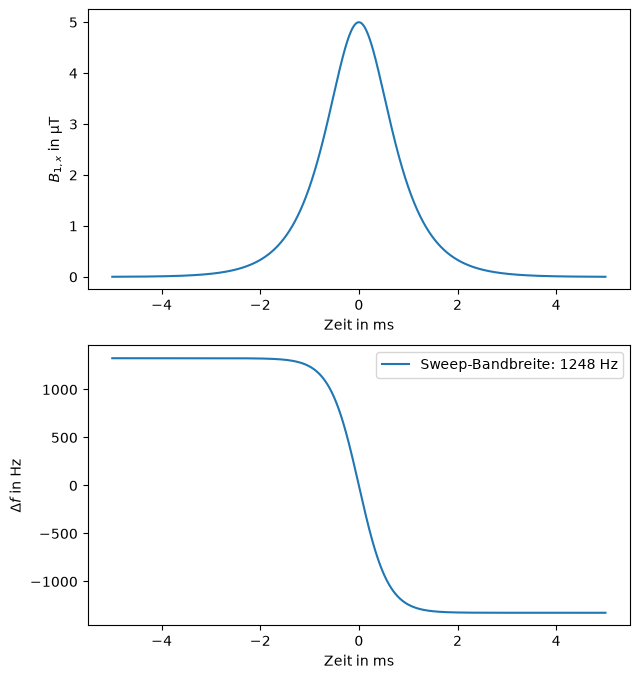

In [106]:
# Amplitude und Frequenz plotten

fig, ax = plt.subplots(2,1, figsize=(7,8))

ax[0].plot(time_values*1e3, amp_values*1e6)
ax[0].set_xlabel("Zeit in ms")
ax[0].set_ylabel("$B_{1,x}$ in µT")

ax[1].plot(time_values*1e3, frequency_values_hz, label = f"Sweep-Bandbreite: {bandbreite(mu, beta):.0f} Hz")
ax[1].set_xlabel("Zeit in ms")
ax[1].set_ylabel(r"$\Delta f$ in Hz")
ax[1].legend()

plt.show()

In [107]:
# Bloch-Gleichung lösen

solution = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0, mu, beta, T_1, T_2), t_eval = time_values)
Mx = solution.y[0]
My = solution.y[1]
Mz = solution.y[2]

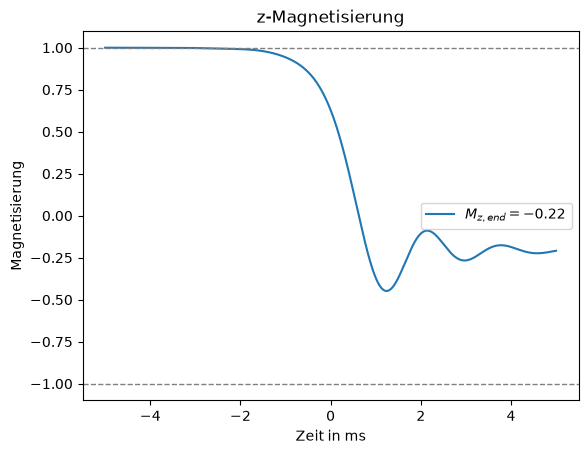

In [108]:
# Magnetisierung plotten

last_times = int(0.05 * len(times))
inversionsgrad = np.mean(Mz[-last_times:])

plt.figure()

plt.plot(times * 1e3, Mz, label = fr"$M_{{z,end}} = {inversionsgrad:.2}$")

plt.axhline(y=1, color="gray", linestyle="--", linewidth=1)
plt.axhline(y=-1, color="gray", linestyle="--", linewidth=1)

plt.xlabel("Zeit in ms")
plt.ylabel("Magnetisierung")
plt.ylim(-1.1,1.1)
plt.title("z-Magnetisierung")
plt.legend()
plt.show()

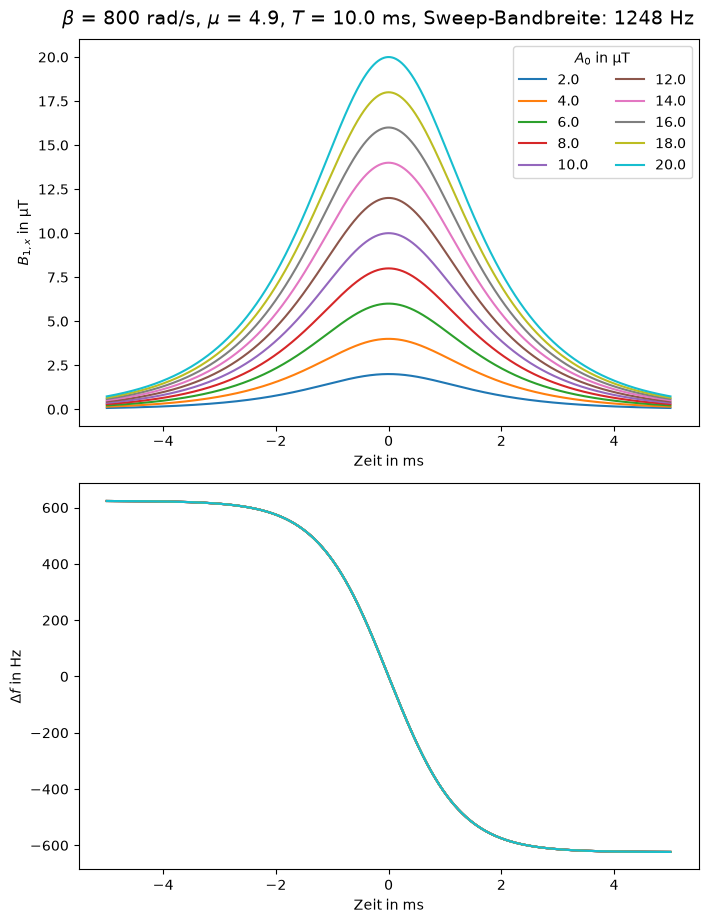

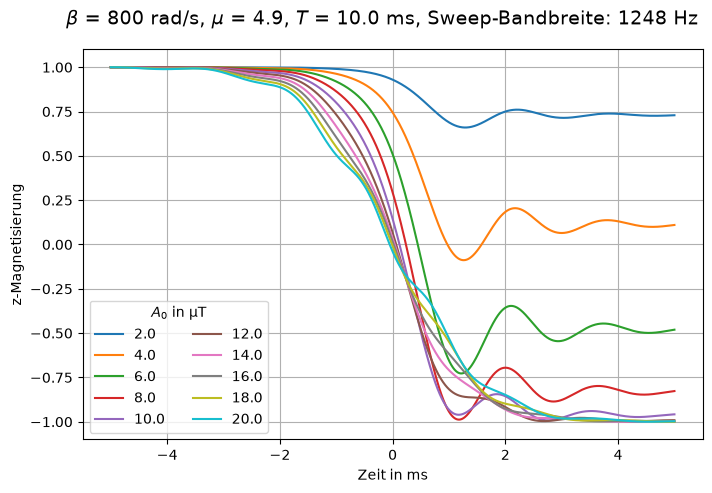

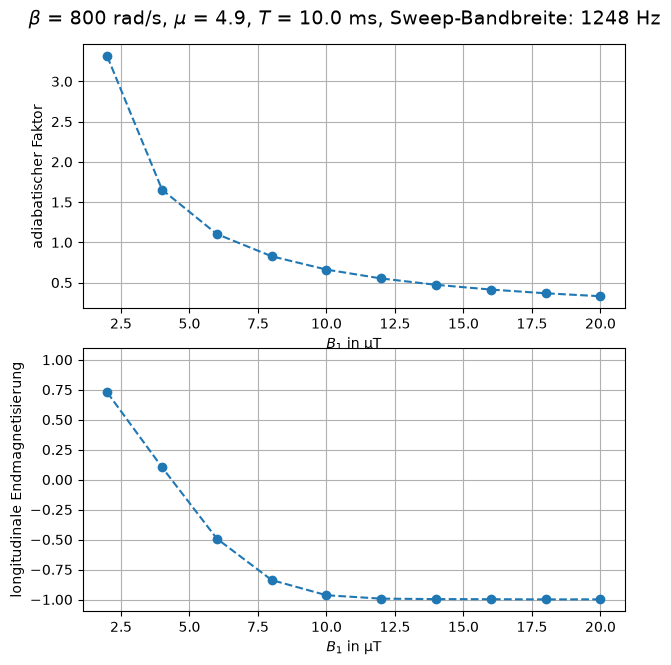

In [ ]:
# Variation A0

A0_range = np.linspace(2e-6, 20e-6, 10)

epsilons = []
inversionsgrade = []

fig1, ax1 = plt.subplots(2,1, figsize=(8,10))
fig1.suptitle(f"$\\beta$ = {beta} rad/s, $\\mu$ = {mu}, $T$ = {2*half_pulse_duration*1e3} ms, Sweep-Bandbreite: {bandbreite(mu, beta):.0f} Hz", 
              fontsize = 14, y=0.96)
fig1.subplots_adjust(top=0.93, bottom=0.10, hspace=0.15)

fig3, ax3 = plt.subplots(1,1, figsize=(8,5))
fig3.suptitle(f"$\\beta$ = {beta} rad/s, $\\mu$ = {mu}, $T$ = {2*half_pulse_duration*1e3} ms, Sweep-Bandbreite: {bandbreite(mu, beta):.0f} Hz", 
              fontsize = 14, y=0.96)
fig3.subplots_adjust(top=0.88, bottom=0.10, hspace=0.2)

for A0_value in A0_range:
    
    amp_values = np.array([B1x(t, A0_value, beta) for t in times])
    frequency_values_rad = np.array([delta_omega(t, mu, beta) for t in times])
    frequency_values_hz = frequency_values_rad / (2 * np.pi)

    ax1[0].plot(times*1e3, amp_values*1e6, label = f"{A0_value*1e6:.1f}")
    ax1[0].legend(title = r"$A_0$ in µT", ncol=2)
    ax1[0].set_xlabel("Zeit in ms")
    ax1[0].set_ylabel(r"$B_{1,x}$ in µT")

    ax1[1].plot(times*1e3, frequency_values_hz)
    ax1[1].set_xlabel("Zeit in ms")
    ax1[1].set_ylabel(r"$\Delta f$ in Hz")


    solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0_value, mu, beta, T_1, T_2), t_eval = time_values)
    Mzs = solutions.y[2]

    ax3.plot(times*1e3, Mzs, label = f"{A0_value*1e6:.1f}")
    ax3.legend(title = r"$A_0$ in µT", ncol=2)
    ax3.set_xlabel("Zeit in ms")
    ax3.set_ylabel("z-Magnetisierung")
    ax3.grid(True)
    ax3.set_ylim(-1.1, 1.1)


    last_times = int(0.05 * len(times))
    inversionsgrad = np.mean(Mzs[-last_times:])
    inversionsgrade.append(inversionsgrad)
    
    epsilon = adiabatic(A0_value, mu, beta)
    epsilons.append(epsilon)
    

fig2, ax2 = plt.subplots(2,1, figsize=(7,7))
fig2.suptitle(f"$\\beta$ = {beta} rad/s, $\\mu$ = {mu}, $T$ = {2*half_pulse_duration*1e3} ms, Sweep-Bandbreite: {bandbreite(mu, beta):.0f} Hz", 
              fontsize = 14, y=0.96)
fig2.subplots_adjust(top=0.91, bottom=0.10, hspace=0.15)

ax2[0].plot(A0_range*1e6, epsilons, "o--")
ax2[0].set_xlabel(r"$B_1$ in µT")
ax2[0].set_ylabel("adiabatischer Faktor")
ax2[0].grid(True)

ax2[1].plot(A0_range*1e6, inversionsgrade, "o--")
ax2[1].set_xlabel(r"$B_1$ in µT")
ax2[1].set_ylabel("longitudinale Endmagnetisierung")
ax2[1].grid(True)
ax2[1].set_ylim(-1.1, 1.1)
ax2[1].yaxis.set_major_locator(MultipleLocator(0.25))

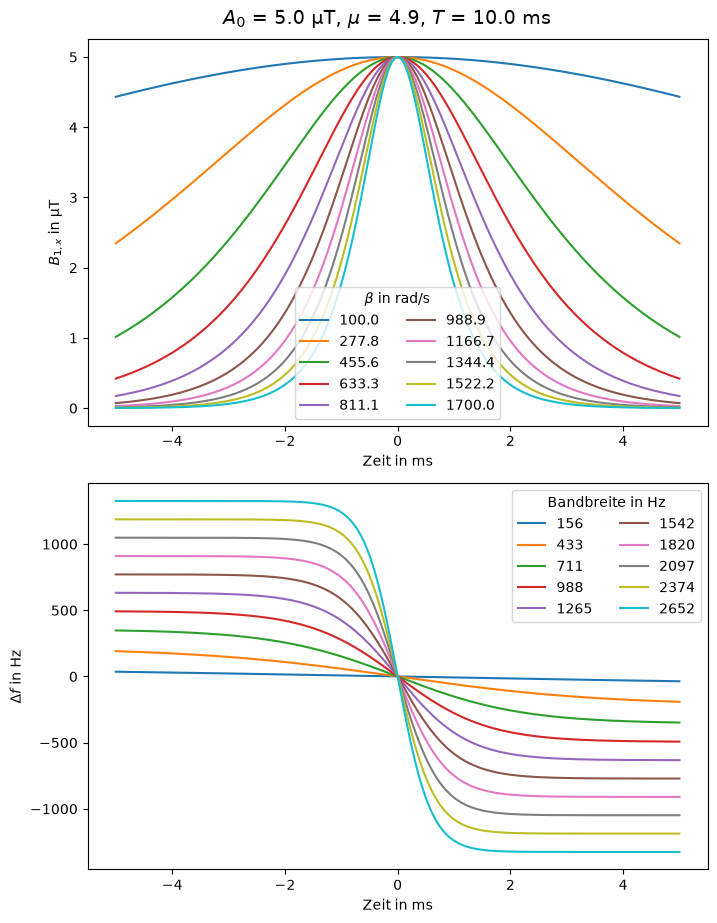

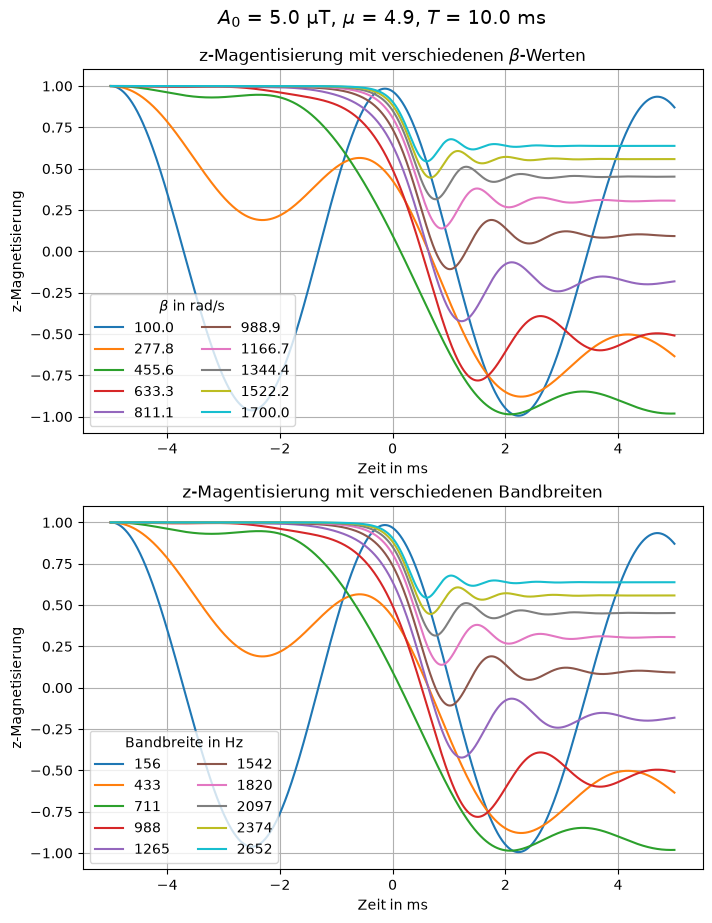

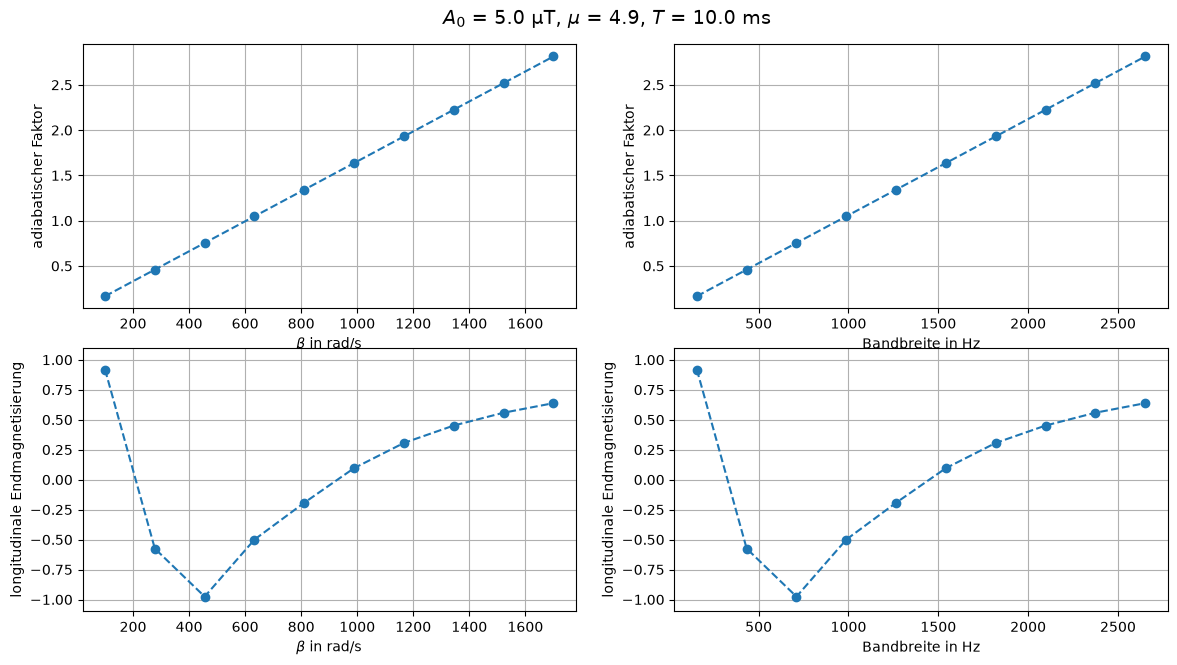

In [ ]:
# Variation beta

beta_range = np.linspace(100, 1700, 10)

bandbreiten = []
epsilons = []
inversionsgrade = []

fig1, ax1 = plt.subplots(2,1, figsize=(8,10))
fig1.suptitle(f"$A_0$ = {A0*1e6} µT, $\\mu$ = {mu}, $T$ = {2*half_pulse_duration*1e3} ms", fontsize = 14, y=0.96)
fig1.subplots_adjust(top=0.93, bottom=0.10, hspace=0.15)

fig3, ax3 = plt.subplots(2,1, figsize=(8,10))
fig3.suptitle(f"$A_0$ = {A0*1e6} µT, $\\mu$ = {mu}, $T$ = {2*half_pulse_duration*1e3} ms", fontsize = 14, y=0.96)
fig3.subplots_adjust(top=0.9, bottom=0.10, hspace=0.2)

for beta_value in beta_range:
    
    amp_values = np.array([B1x(t, A0, beta_value) for t in times])
    frequency_values_rad = np.array([delta_omega(t, mu, beta_value) for t in times])
    frequency_values_hz = frequency_values_rad / (2 * np.pi)

    bandbreite_values = bandbreite(mu, beta_value)

    ax1[0].plot(times*1e3, amp_values*1e6, label = f"{beta_value:.1f}")
    ax1[0].legend(title = r"$\beta$ in rad/s", ncol=2)
    ax1[0].set_xlabel("Zeit in ms")
    ax1[0].set_ylabel(r"$B_{1,x}$ in µT")

    ax1[1].plot(times*1e3, frequency_values_hz, label = f"{bandbreite_values:.0f}")
    ax1[1].legend(title = "Bandbreite in Hz", ncol=2)
    ax1[1].set_xlabel("Zeit in ms")
    ax1[1].set_ylabel(r"$\Delta f$ in Hz")


    solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0, mu, beta_value, T_1, T_2), t_eval = time_values)
    Mzs = solutions.y[2]

    ax3[0].plot(times*1e3, Mzs, label = f"{beta_value:.1f}")
    ax3[0].legend(title = r"$\beta$ in rad/s", ncol=2, loc="lower left")
    ax3[0].set_xlabel("Zeit in ms")
    ax3[0].set_ylabel("z-Magnetisierung")
    ax3[0].set_title(r"z-Magentisierung mit verschiedenen $\beta$-Werten")
    ax3[0].grid(True)
    ax3[0].set_ylim(-1.1, 1.1)

    ax3[1].plot(times*1e3, Mzs, label = f"{bandbreite_values:.0f}")
    ax3[1].legend(title = "Bandbreite in Hz", ncol=2, loc="lower left")
    ax3[1].set_xlabel("Zeit in ms")
    ax3[1].set_ylabel("z-Magnetisierung")
    ax3[1].set_title("z-Magentisierung mit verschiedenen Bandbreiten")
    ax3[1].grid(True)
    ax3[1].set_ylim(-1.1, 1.1)
    

    bandbreiten.append(bandbreite_values)

    last_times = int(0.05 * len(times))
    inversionsgrad = np.mean(Mzs[-last_times:])
    inversionsgrade.append(inversionsgrad)

    epsilon = adiabatic(A0, mu, beta_value)
    epsilons.append(epsilon)


fig2, ax2 = plt.subplots(2,2, figsize=(14,7))
fig2.suptitle(f"$A_0$ = {A0*1e6} µT, $\\mu$ = {mu}, $T$ = {2*half_pulse_duration*1e3} ms", fontsize = 14, y=0.96)
fig2.subplots_adjust(top=0.91, bottom=0.10, hspace=0.15)

ax2[0,0].plot(beta_range, epsilons, "o--")
ax2[0,0].set_xlabel(r"$\beta$ in rad/s")
ax2[0,0].set_ylabel("adiabatischer Faktor")
ax2[0,0].grid(True)

ax2[1,0].plot(beta_range, inversionsgrade, "o--")
ax2[1,0].set_xlabel(r"$\beta$ in rad/s")
ax2[1,0].set_ylabel("longitudinale Endmagnetisierung")
ax2[1,0].grid(True)
ax2[1,0].set_ylim(-1.1, 1.1)
ax2[1,0].yaxis.set_major_locator(MultipleLocator(0.25))

ax2[0,1].plot(bandbreiten, epsilons, "o--")
ax2[0,1].set_xlabel("Bandbreite in Hz")
ax2[0,1].set_ylabel("adiabatischer Faktor")
ax2[0,1].grid(True)

ax2[1,1].plot(bandbreiten, inversionsgrade, "o--")
ax2[1,1].set_xlabel("Bandbreite in Hz")
ax2[1,1].set_ylabel("longitudinale Endmagnetisierung")
ax2[1,1].grid(True)
ax2[1,1].set_ylim(-1.1, 1.1)
ax2[1,1].yaxis.set_major_locator(MultipleLocator(0.25))

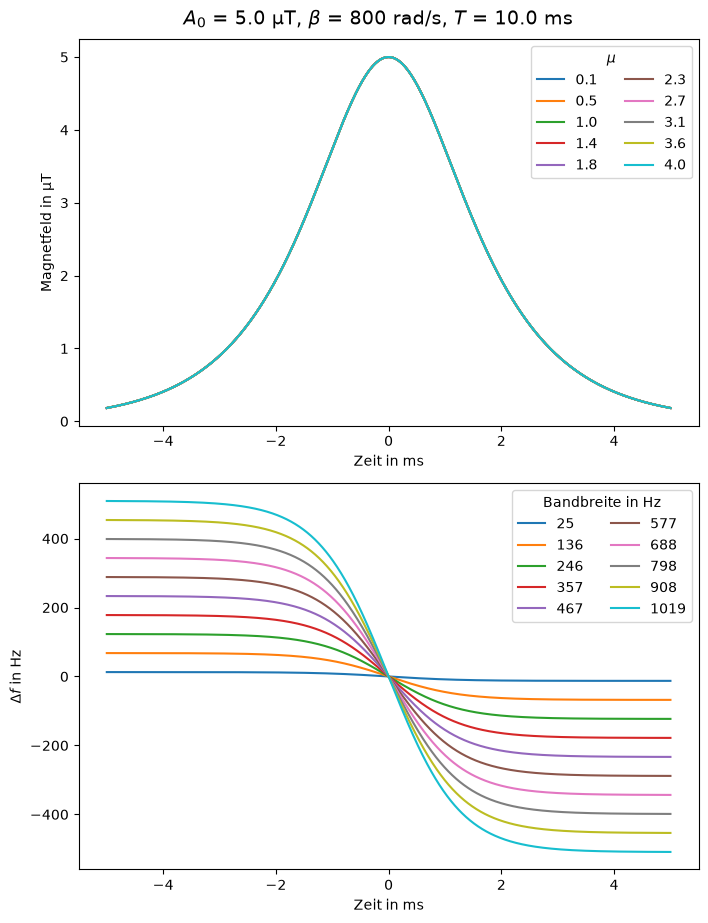

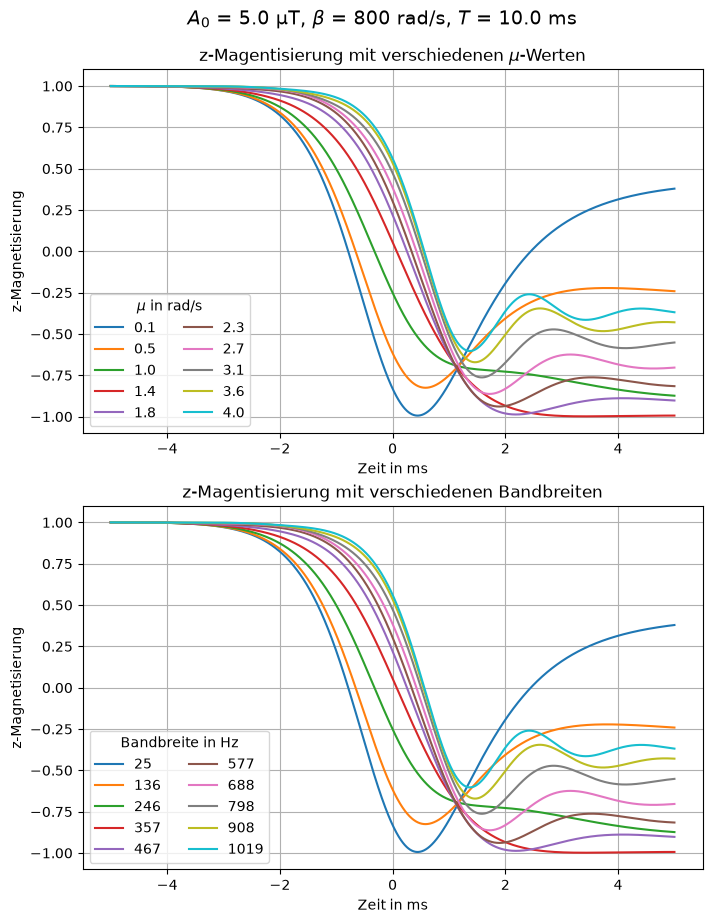

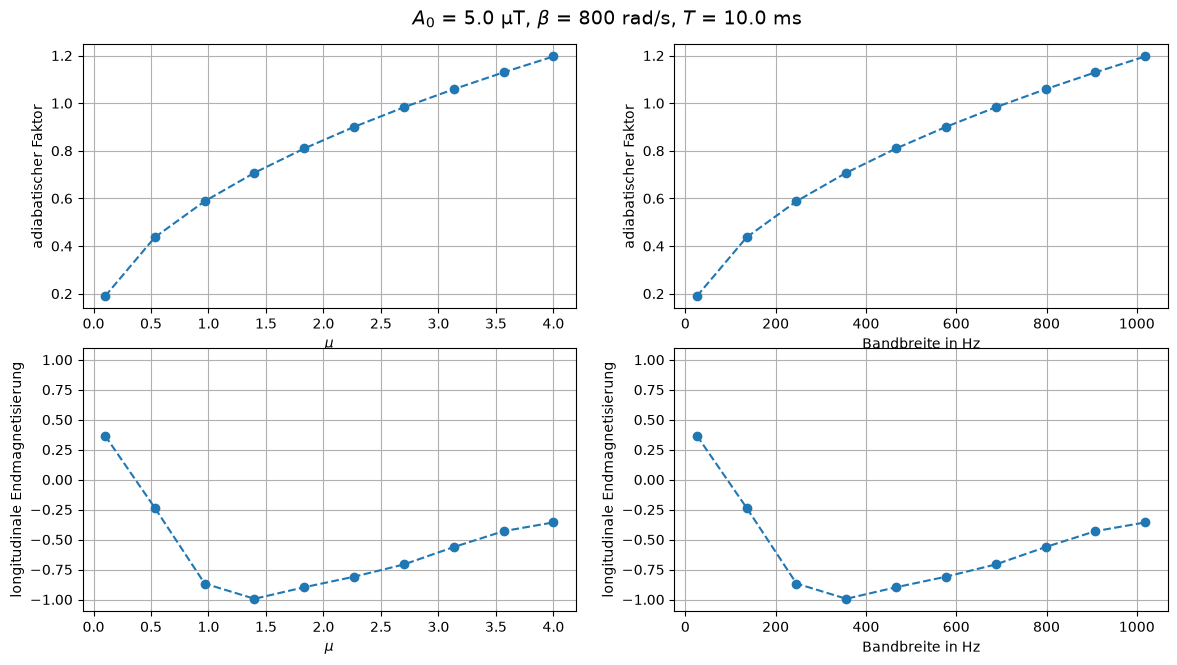

In [154]:
# Variation mu

mu_range = np.linspace(0.1, 4, 10)

bandbreiten = []
epsilons = []
inversionsgrade = []

fig1, ax1 = plt.subplots(2,1, figsize=(8,10))
fig1.suptitle(f"$A_0$ = {A0*1e6} µT, $\\beta$ = {beta} rad/s, $T$ = {2*half_pulse_duration*1e3} ms", fontsize = 14, y=0.96)
fig1.subplots_adjust(top=0.93, bottom=0.10, hspace=0.15)

fig3, ax3 = plt.subplots(2,1, figsize=(8,10))
fig3.suptitle(f"$A_0$ = {A0*1e6} µT, $\\beta$ = {beta} rad/s, $T$ = {2*half_pulse_duration*1e3} ms", fontsize = 14, y=0.96)
fig3.subplots_adjust(top=0.9, bottom=0.10, hspace=0.2)

for mu_value in mu_range:
    
    amp_values = np.array([B1x(t, A0, beta) for t in times])
    frequency_values_rad = np.array([delta_omega(t, mu_value, beta) for t in times])
    frequency_values_hz = frequency_values_rad / (2 * np.pi)
    
    bandbreite_values = bandbreite(mu_value, beta)

    ax1[0].plot(times*1e3, amp_values*1e6, label = f"{mu_value:.1f}")
    ax1[0].legend(title = r"$\mu$", ncol=2)
    ax1[0].set_xlabel("Zeit in ms")
    ax1[0].set_ylabel("Magnetfeld in µT")

    ax1[1].plot(times*1e3, frequency_values_hz, label = f"{bandbreite_values:.0f}")
    ax1[1].legend(title = "Bandbreite in Hz", ncol=2)
    ax1[1].set_xlabel("Zeit in ms")
    ax1[1].set_ylabel(r"$\Delta f$ in Hz")


    solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0, mu_value, beta, T_1, T_2), t_eval = time_values)
    Mzs = solutions.y[2]

    ax3[0].plot(times*1e3, Mzs, label = f"{mu_value:.1f}")
    ax3[0].legend(title = r"$\mu$ in rad/s", ncol=2, loc="lower left")
    ax3[0].set_xlabel("Zeit in ms")
    ax3[0].set_ylabel("z-Magnetisierung")
    ax3[0].set_title(r"z-Magentisierung mit verschiedenen $\mu$-Werten")
    ax3[0].grid(True)
    ax3[0].set_ylim(-1.1, 1.1)

    ax3[1].plot(times*1e3, Mzs, label = f"{bandbreite_values:.0f}")
    ax3[1].legend(title = "Bandbreite in Hz", ncol=2, loc="lower left")
    ax3[1].set_xlabel("Zeit in ms")
    ax3[1].set_ylabel("z-Magnetisierung")
    ax3[1].set_title("z-Magentisierung mit verschiedenen Bandbreiten")
    ax3[1].grid(True)
    ax3[1].set_ylim(-1.1, 1.1)


    bandbreiten.append(bandbreite_values)

    last_times = int(0.05 * len(times))
    inversionsgrad = np.mean(Mzs[-last_times:])
    inversionsgrade.append(inversionsgrad)

    epsilon = adiabatic(A0, mu_value, beta)
    epsilons.append(epsilon)

    
fig2, ax2 = plt.subplots(2,2, figsize=(14,7))
fig2.suptitle(f"$A_0$ = {A0*1e6} µT, $\\beta$ = {beta} rad/s, $T$ = {2*half_pulse_duration*1e3} ms", fontsize = 14, y=0.96)
fig2.subplots_adjust(top=0.91, bottom=0.10, hspace=0.15)

ax2[0,0].plot(mu_range, epsilons, "o--")
ax2[0,0].set_xlabel(r"$\mu$")
ax2[0,0].set_ylabel("adiabatischer Faktor")
ax2[0,0].grid(True)

ax2[1,0].plot(mu_range, inversionsgrade, "o--")
ax2[1,0].set_xlabel(r"$\mu$")
ax2[1,0].set_ylabel("longitudinale Endmagnetisierung")
ax2[1,0].grid(True)
ax2[1,0].set_ylim(-1.1, 1.1)
ax2[1,0].yaxis.set_major_locator(MultipleLocator(0.25))

ax2[0,1].plot(bandbreiten, epsilons, "o--")
ax2[0,1].set_xlabel("Bandbreite in Hz")
ax2[0,1].set_ylabel("adiabatischer Faktor")
ax2[0,1].grid(True)

ax2[1,1].plot(bandbreiten, inversionsgrade, "o--")
ax2[1,1].set_xlabel("Bandbreite in Hz")
ax2[1,1].set_ylabel("longitudinale Endmagnetisierung")
ax2[1,1].grid(True)
ax2[1,1].set_ylim(-1.1, 1.1)
ax2[1,1].yaxis.set_major_locator(MultipleLocator(0.25))

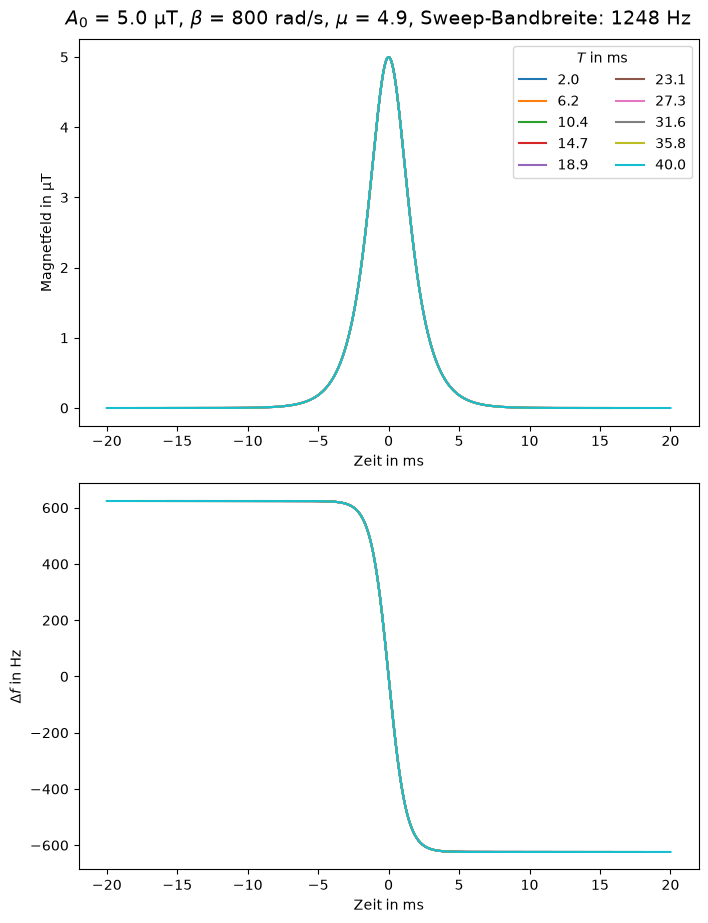

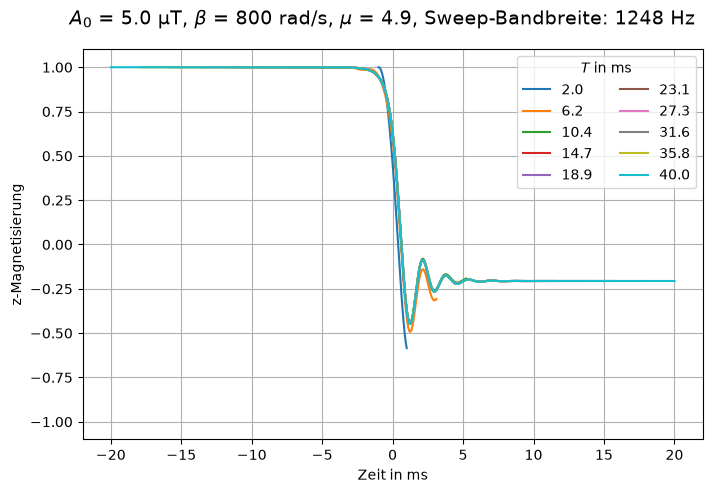

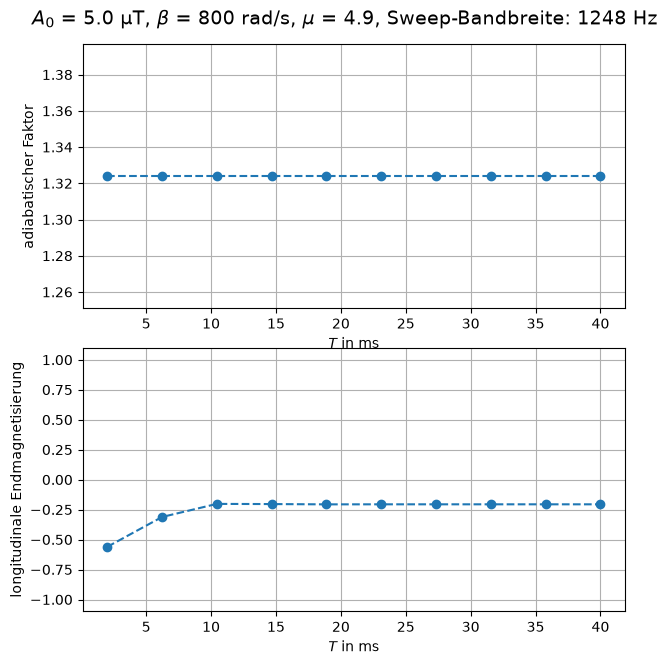

In [161]:
# Variation T

T_range = np.linspace(1e-3, 20e-3, 10)

epsilons = []
inversionsgrade = []

fig1, ax1 = plt.subplots(2,1, figsize=(8,10))
fig1.suptitle(f"$A_0$ = {A0*1e6} µT, $\\beta$ = {beta} rad/s, $\\mu$ = {mu}, Sweep-Bandbreite: {bandbreite(mu, beta):.0f} Hz", 
              fontsize = 14, y=0.96)
fig1.subplots_adjust(top=0.93, bottom=0.10, hspace=0.15)

fig3, ax3 = plt.subplots(1,1, figsize=(8,5))
fig3.suptitle(f"$A_0$ = {A0*1e6} µT, $\\beta$ = {beta} rad/s, $\\mu$ = {mu}, Sweep-Bandbreite: {bandbreite(mu, beta):.0f} Hz", 
              fontsize = 14, y=0.96)
fig3.subplots_adjust(top=0.88, bottom=0.10, hspace=0.2)

for T_value in T_range:

    t_start = - T_value
    t_end = T_value
    times = np.linspace(t_start, t_end, 2000)

    amp_values = np.array([B1x(t, A0, beta) for t in times])
    frequency_values_rad = np.array([delta_omega(t, mu, beta) for t in times])
    frequency_values_hz = frequency_values_rad / (2 * np.pi)

    ax1[0].plot(times*1e3, amp_values*1e6, label = f"{2*T_value*1e3:.1f}")
    ax1[0].legend(title = r"$T$ in ms", ncol=2)
    ax1[0].set_xlabel("Zeit in ms")
    ax1[0].set_ylabel("Magnetfeld in µT")

    ax1[1].plot(times*1e3, frequency_values_hz)
    ax1[1].set_xlabel("Zeit in ms")
    ax1[1].set_ylabel(r"$\Delta f$ in Hz")


    solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0, mu, beta, T_1, T_2), t_eval = times)
    Mzs = solutions.y[2]
    
    ax3.plot(times*1e3, Mzs, label = f"{2*T_value*1e3:.1f}")
    ax3.legend(title = r"$T$ in ms", ncol=2)
    ax3.set_xlabel("Zeit in ms")
    ax3.set_ylabel("z-Magnetisierung")
    ax3.grid(True)
    ax3.set_ylim(-1.1, 1.1)


    last_times = int(0.05 * len(times))
    inversionsgrad = np.mean(Mzs[-last_times:])
    inversionsgrade.append(inversionsgrad)

    epsilon = adiabatic(A0, mu, beta)
    epsilons.append(epsilon)

    
fig2, ax2 = plt.subplots(2,1, figsize=(7,7))
fig2.suptitle(f"$A_0$ = {A0*1e6} µT, $\\beta$ = {beta} rad/s, $\\mu$ = {mu}, Sweep-Bandbreite: {bandbreite(mu, beta):.0f} Hz", 
              fontsize = 14, y=0.96)
fig2.subplots_adjust(top=0.91, bottom=0.10, hspace=0.15)

ax2[0].plot(2*T_range*1e3, epsilons, "o--")
ax2[0].set_xlabel(r"$T$ in ms")
ax2[0].set_ylabel("adiabatischer Faktor")
ax2[0].grid(True)

ax2[1].plot(2*T_range*1e3, inversionsgrade, "o--")
ax2[1].set_xlabel(r"$T$ in ms")
ax2[1].set_ylabel("longitudinale Endmagnetisierung")
ax2[1].grid(True)
ax2[1].set_ylim(-1.1, 1.1)
ax2[1].yaxis.set_major_locator(MultipleLocator(0.25))    

In [56]:
# Variation A0 und T

T_range = np.linspace(0.1e-3, 15e-3, 30)
A0_range = np.linspace(2e-6, 12e-6, 10)

epsilons = []
inversionsgrade = []
winkels = []

for T_value in T_range:

    t_start = - T_value
    t_end = T_value
    times = np.linspace(t_start, t_end, 2000)

    epsilons2 = []
    inversionsgrade2 = []
    winkels2 = []

    for A0_value in A0_range:

        epsilon = np.round(adiabatic(A0_value, mu, beta),2)
        epsilons2.append(epsilon)

        solutions = solve_ivp(bloch_rot, (t_start, t_end), M0, args=(A0_value, mu, beta, T_1, T_2), t_eval = times)
        Mzs = solutions.y[2]

        last_times = int(0.05 * len(times))
        inversionsgrad = np.mean(Mzs[-last_times:])
        # inversionsgrad = Mzs[-1]
        inversionsgrade2.append(inversionsgrad)

        Mz_end = np.mean(Mzs[-last_times:])
        Mz_end = np.clip(Mz_end, -1, 1)
        winkel = np.degrees(np.arccos(Mz_end))
        winkels2.append(winkel)

    epsilons.append(epsilons2)
    inversionsgrade.append(inversionsgrade2)  
    winkels.append(winkels2)

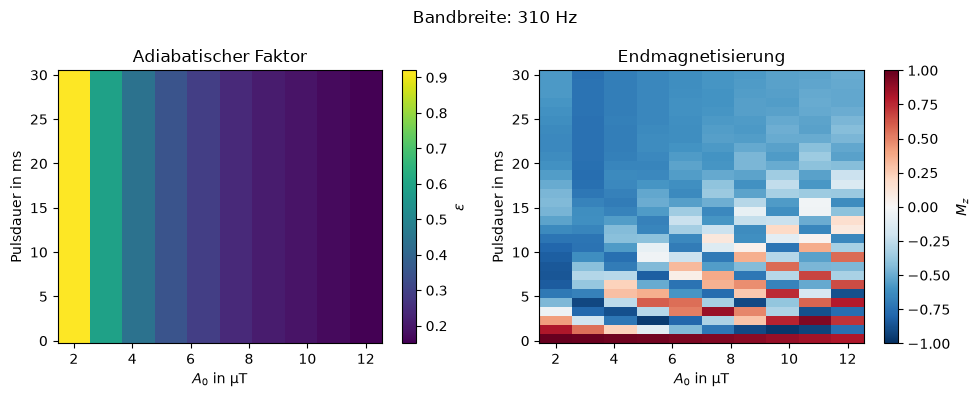

In [57]:
fig, ax = plt.subplots(1,2, figsize=(10, 4))

im1 = ax[0].pcolormesh(A0_range*1e6, 2*T_range*1e3, epsilons, shading="auto")

ax[0].set_xlabel(r"$A_0$ in µT")
ax[0].set_ylabel("Pulsdauer in ms")
ax[0].set_title("Adiabatischer Faktor")

fig.colorbar(im1, ax=ax[0], label=r"$\epsilon$")

im2 = ax[1].pcolormesh(A0_range*1e6, 2*T_range*1e3, inversionsgrade, shading="auto",
                        cmap="RdBu_r", vmin=-1, vmax=1)

ax[1].set_xlabel(r"$A_0$ in µT")
ax[1].set_ylabel("Pulsdauer in ms")
ax[1].set_title("Endmagnetisierung")

fig.colorbar(im2, ax=ax[1], label=r"$M_z$")

fig.suptitle(
    f"Bandbreite: {delta_f(mu,beta):.0f} Hz"
)
fig.tight_layout()
plt.show()

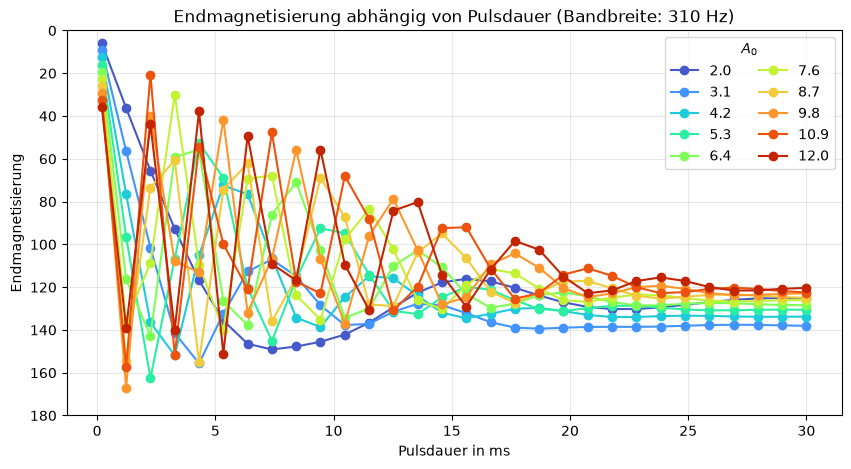

In [58]:
fig, ax = plt.subplots(figsize=(10,5))

# colors = ["blue", "red", "green", "orange", "purple", "black", "cyan", "magenta", "brown", "gray"]
colors = plt.cm.turbo(np.linspace(0.1, 0.9, len(A0_range)))

for i, A0_value in enumerate(A0_range):
    ax.plot(2*T_range*1e3, np.array(winkels)[:,i], "-o", color=colors[i], label=f"{A0_value*1e6:.1f}")

ax.set_xlabel("Pulsdauer in ms")
ax.set_ylabel("Endmagnetisierung")
ax.set_ylim(180, 0)
ax.set_title(f"Endmagnetisierung abhängig von Pulsdauer (Bandbreite: {delta_f(mu,beta):.0f} Hz)")
ax.grid(True, alpha=0.3)
ax.legend(title=r"$A_0$", ncol=2)
plt.show()